<div style="background: linear-gradient(135deg, #114F6A 0%, #1FA4B1 100%); padding: 28px; border-radius: 12px; color: #FFFFFF; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; box-shadow: 0 4px 12px rgba(17, 79, 106, 0.2);">
  <h1 style="margin: 0; font-size: 26px; letter-spacing: 1px; color: #FFFFFF;">PROYEK UTS PRAKTIKUM DEEP LEARNING</h1>
  <p style="margin: 6px 0 20px 0; font-size: 14px; color: #E0F7FA; opacity: 0.95;">Implementasi Sequence Deep Learning (RNN / LSTM) untuk Analisis Sentimen & Time-Series Forecasting</p>
  
  <div style="background-color: #FFFFFF; color: #1E293B; padding: 18px 22px; border-radius: 8px; border-left: 6px solid #114F6A;">
    <h3 style="margin: 0 0 12px 0; color: #114F6A; font-size: 16px; border-bottom: 2px solid #E2E8F0; padding-bottom: 6px;">DATA DIRI & KONFIGURASI PROYEK</h3>
    <table style="width: 100%; border-collapse: collapse; font-size: 14px; color: #1E293B;">
      <tr>
        <td style="padding: 6px 0; width: 220px; font-weight: bold; color: #114F6A;">Nama Lengkap</td>
        <td style="padding: 6px 0;">: Dzaky Hilmy Haidar</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">NIM</td>
        <td style="padding: 6px 0;">: 202432044</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">Kelas</td>
        <td style="padding: 6px 0;">: C</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">Kategori Tugas (Sesuai NIM)</td>
        <td style="padding: 6px 0;">: Forecasting Time-Series (NIM Genap)</td>
      </tr>
      <tr>
        <td style="padding: 6px 0; font-weight: bold; color: #114F6A;">Algoritma yang Dipilih</td>
        <td style="padding: 6px 0;">: <span style="background-color: #1FA4B1; color: #FFFFFF; padding: 2px 10px; border-radius: 4px; font-weight: bold;">LSTM</span></td>
      </tr>
    </table>
  </div>
</div>

<div style="border: 1px solid #CBD5E1; border-radius: 10px; overflow: hidden; font-family: 'Segoe UI', sans-serif; margin-top: 12px;">
  <div style="background-color: #114F6A; color: #FFFFFF; padding: 12px 20px; font-weight: bold; font-size: 16px; border-bottom: 4px solid #1FA4B1;">
    BAB 1 — LATAR BELAKANG MASALAH
  </div>
  <div style="background-color: #FFFFFF; color: #334155; padding: 20px; line-height: 1.7; font-size: 14px;">
    <p style="margin-top: 0;">
      <b>1. Deskripsi Permasalahan:</b><br>
      Konsumsi listrik rumah tangga terus meningkat seiring bertambahnya peralatan elektronik, sementara rumah pintar dengan panel surya membuat pola konsumsi dan produksi energi semakin dinamis. Peramalan konsumsi listrik jangka pendek membantu penghuni menjadwalkan alat berdaya besar, mengelola energi surya, menekan biaya, dan mendeteksi lonjakan konsumsi yang tidak wajar. Data konsumsi per jam adalah deret waktu dengan ketergantungan temporal yang kuat (pola harian, mingguan, dan pengaruh cuaca), sehingga pendekatan Sequence Deep Learning lebih tepat dibanding model yang memperlakukan tiap observasi secara independen.
    </p>
    <p style="margin-bottom: 0;">
      <b>2. Tujuan Pemodelan & Alasan Pemilihan Algoritma:</b><br>
      Tujuan: membangun model peramalan konsumsi listrik rumah per jam (<code>use [kW]</code>) dan mengevaluasi kemampuannya mengikuti data aktual pada data uji. Algoritma LSTM dipilih karena RNN standar rentan mengalami vanishing gradient pada sekuens panjang, sedangkan LSTM memiliki cell state serta forget, input, dan output gate yang mampu mempertahankan informasi pola harian yang berulang tiap 24 jam.
    </p>
  </div>
</div>

<div style="border: 1px solid #CBD5E1; border-radius: 10px; overflow: hidden; font-family: sans-serif; margin-top: 10px;">
<div style="background-color: #114F6A; color: #FFFFFF; padding: 12px 20px; font-weight: bold; font-size: 15px; border-bottom: 4px solid #1FA4B1;">INFORMASI &amp; KARAKTERISTIK DATASET KAGGLE</div>
<div style="background-color: #F8FAFC; color: #334155; padding: 18px 20px; font-size: 14px; line-height: 1.6;">
<div style="background-color: #E0F7FA; border-left: 5px solid #1FA4B1; padding: 12px 16px; border-radius: 4px; margin-bottom: 14px;">
<b style="color: #114F6A;">Nama Dataset:</b> Smart Home Dataset with Weather Information (Taranvee)<br>
<b style="color: #114F6A;">Link Dataset Kaggle:</b> <a href="https://www.kaggle.com/datasets/taranvee/smart-home-dataset-with-weather-information" target="_blank" style="color: #114F6A; font-weight: bold; text-decoration: underline;">https://www.kaggle.com/datasets/taranvee/smart-home-dataset-with-weather-information</a>
</div>
<div style="margin-bottom: 12px;">
<b style="color: #114F6A;">Penjelasan Umum Dataset:</b><br>
Berkas <code>HomeC.csv</code> berisi data konsumsi energi satu rumah pintar dengan resolusi 1 menit: 503.910 baris valid dan 32 kolom (1 baris terakhir korup dan dibuang). Kolom meliputi konsumsi total (<code>use [kW]</code>), produksi surya (<code>gen [kW]</code>), konsumsi per alat/ruangan (14 kolom), serta 11 variabel cuaca numerik dan 2 kolom kategorikal (<code>icon</code>, <code>summary</code>). Target peramalan adalah <code>use [kW]</code> yang diagregasi menjadi rata-rata per jam (8.399 titik data). Kolom <code>time</code> berisi indeks berurutan per menit (bukan detik sebenarnya), sehingga direkonstruksi menjadi timestamp mulai 1 Januari 2016.
</div>
</div>
</div>

<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">1. IMPORT LIBRARY</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Memuat pustaka komputasi numerik, manipulasi data, visualisasi grafik, dan kerangka kerja PyTorch.</p>
</div>

In [1]:
#202432044_DzakyHilmyHaidar
!pip install torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Seed agar hasil dapat direproduksi
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Pilih perangkat komputasi (GPU jika tersedia, jika tidak CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Perangkat yang digunakan:', device)

Perangkat yang digunakan: cpu


<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">2. PRA-PEMROSESAN DATA (PREPROCESSING)</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Memuat dataset, membersihkan data, melakukan normalisasi / tokenisasi sekuens, serta membagi data latih dan data uji.</p>
</div>

Ukuran awal dataset (baris, kolom): (503911, 32)
Ukuran setelah dibersihkan      : (503910, 32)
Rentang waktu: 2016-01-01 00:00:00 s/d 2016-12-15 22:29:00
Jumlah titik data per jam: 8399 | nilai hilang: 0
count    8399.000
mean        0.859
std         0.807
min         0.001
25%         0.430
50%         0.676
75%         1.017
max         9.580
Name: use [kW], dtype: float64


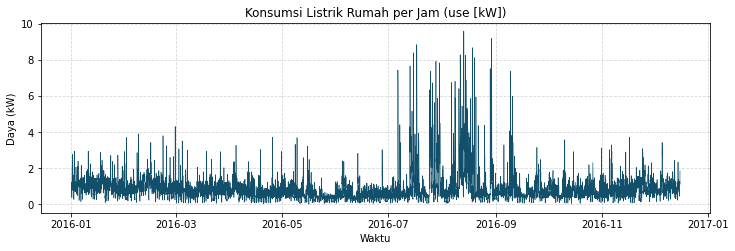

In [2]:
#202432044_DzakyHilmyHaidar
# Lokasi berkas dataset 
DATA_PATH = 'HomeC.csv'

# 1. Memuat dataset
df = pd.read_csv(DATA_PATH, low_memory=False)
print('Ukuran awal dataset (baris, kolom):', df.shape)

# 2. Pembersihan Data
df = df[pd.to_numeric(df['time'], errors='coerce').notna()].copy()
df = df.dropna(subset=['use [kW]'])
print('Ukuran setelah dibersihkan      :', df.shape)

# 3. Rekonstruksi indeks waktu: 'time' hanya indeks berurutan per menit, bukan detik
df.index = pd.date_range(start='2016-01-01 00:00', periods=len(df), freq='min')
df.index.name = 'timestamp'
print('Rentang waktu:', df.index[0], 's/d', df.index[-1])

# 4. Agregasi menit -> rata-rata per jam pada kolom target
series = df['use [kW]'].resample('60min').mean()
print('Jumlah titik data per jam:', len(series), '| nilai hilang:', series.isna().sum())
print(series.describe().round(3))

# 5. Visualisasi eksplorasi deret waktu per jam
plt.figure(figsize=(12, 3.5))
plt.plot(series.index, series.values, color='#114F6A', linewidth=0.6)
plt.title('Konsumsi Listrik Rumah per Jam (use [kW])')
plt.xlabel('Waktu')
plt.ylabel('Daya (kW)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [3]:
#202432044_DzakyHilmyHaidar
WINDOW = 24        # panjang jendela: 24 jam terakhir sebagai input
TRAIN_RATIO = 0.8  # 80% data awal untuk latih, 20% akhir untuk uji (urut waktu)
BATCH_SIZE = 64

# 1. Ubah deret menjadi array 2D (n, 1) bertipe float32
values = series.values.astype(np.float32).reshape(-1, 1)
split_idx = int(len(values) * TRAIN_RATIO)

# 2. Normalisasi Min-Max; parameter hanya dihitung dari data latih (mencegah kebocoran data)
data_min = values[:split_idx].min()
data_max = values[:split_idx].max()
scaled = (values - data_min) / (data_max - data_min)

# 3. Sliding window: 24 jam -> 1 jam berikutnya
def create_sequences(data, window):
    X, y = [], []
    for i in range(len(data) - window):
        X.append(data[i:i + window])
        y.append(data[i + window])
    return np.array(X), np.array(y)

X_all, y_all = create_sequences(scaled, WINDOW)

# 4. Pembagian latih/uji berdasarkan indeks target (target ke-i berada di indeks i + WINDOW)
train_n = split_idx - WINDOW
X_train, y_train = X_all[:train_n], y_all[:train_n]
X_test, y_test = X_all[train_n:], y_all[train_n:]
test_time = series.index[split_idx:]   # label waktu untuk plot data uji

# 5. Konversi ke PyTorch Tensor
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

# 6. TensorDataset dan DataLoader
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)

print('X_train:', tuple(X_train.shape), '| y_train:', tuple(y_train.shape))
print('X_test :', tuple(X_test.shape), '| y_test :', tuple(y_test.shape))

X_train: (6695, 24, 1) | y_train: (6695, 1)
X_test : (1680, 24, 1) | y_test : (1680, 1)


<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">3. PEMODELAN ARSITEKTUR JARINGAN (RNN / LSTM)</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Mendefinisikan kelas arsitektur model sekuensial menggunakan modul torch.nn sesuai algoritma yang dipilih.</p>
</div>

In [4]:
#202432044_DzakyHilmyHaidar
class SequenceModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=2, dropout=0.2):
        super(SequenceModel, self).__init__()
        # Lapisan LSTM: membaca sekuens 24 jam dan memperbarui hidden state & cell state
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True, dropout=dropout)
        # Lapisan linear: memetakan hidden state terakhir menjadi 1 nilai prediksi
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # x: (batch, 24, 1) -> out: (batch, 24, hidden_size)
        out, _ = self.lstm(x)
        # Ambil hidden state pada time-step terakhir, lalu prediksi jam berikutnya
        return self.fc(out[:, -1, :])

<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">4. INISIASI HYPERPARAMETER & PROSES PELATIHAN (TRAINING)</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Menentukan konfigurasi hyperparameter (learning rate, epochs, loss function, optimizer) dan menjalankan siklus pelatihan model.</p>
</div>

In [5]:
#202432044_DzakyHilmyHaidar
# 1. Hyperparameter
epochs = 30
learning_rate = 0.001
hidden_size = 64
num_layers = 2

# 2. Model, fungsi loss, dan optimizer
model = SequenceModel(input_size=1, hidden_size=hidden_size, num_layers=num_layers).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# 3. Riwayat loss untuk visualisasi
train_losses = []
test_losses = []

# 4. Training loop
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()                                        # reset gradien
        pred = model(xb)                                             # forward pass
        loss = criterion(pred, yb)                                   # hitung MSE
        loss.backward()                                              # backpropagation
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)   # cegah gradien meledak
        optimizer.step()                                             # perbarui bobot
        running_loss += loss.item() * xb.size(0)
    train_loss = running_loss / len(train_loader.dataset)

    # Evaluasi pada data uji (tanpa gradien)
    model.eval()
    test_running = 0.0
    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            test_running += criterion(model(xb), yb).item() * xb.size(0)
    test_loss = test_running / len(test_loader.dataset)

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f'Epoch [{epoch + 1:02d}/{epochs}] | Train Loss: {train_loss:.6f} | Test Loss: {test_loss:.6f}')

Epoch [01/30] | Train Loss: 0.009271 | Test Loss: 0.002290
Epoch [05/30] | Train Loss: 0.003613 | Test Loss: 0.001319
Epoch [10/30] | Train Loss: 0.003348 | Test Loss: 0.001335
Epoch [15/30] | Train Loss: 0.003297 | Test Loss: 0.001278
Epoch [20/30] | Train Loss: 0.003267 | Test Loss: 0.001290
Epoch [25/30] | Train Loss: 0.003208 | Test Loss: 0.001322
Epoch [30/30] | Train Loss: 0.003162 | Test Loss: 0.001304


<div style="background-color: #114F6A; color: #FFFFFF; padding: 10px 18px; border-radius: 8px; border-left: 8px solid #1FA4B1; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <h3 style="margin: 0; font-size: 16px; color: #FFFFFF;">5. VISUALISASI LOSS TRAINING & PERBANDINGAN PREDIKSI VS AKTUAL</h3>
  <p style="margin: 4px 0 0 0; font-size: 12px; color: #E0F7FA;">Menampilkan grafik konvergensi nilai Loss terhadap Epoch dan grafik evaluasi perbandingan hasil prediksi model terhadap data aktual.</p>
</div>

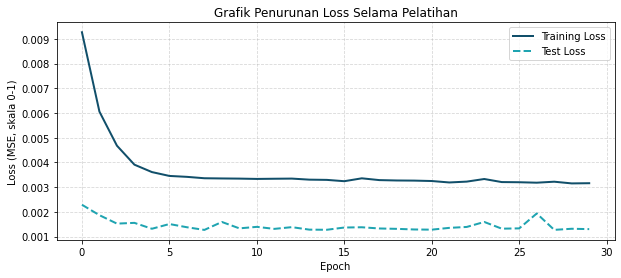

MAE   : 0.2344 kW
RMSE  : 0.3459 kW
R2    : 0.4826
RMSE baseline naive (jam sebelumnya): 0.3657 kW


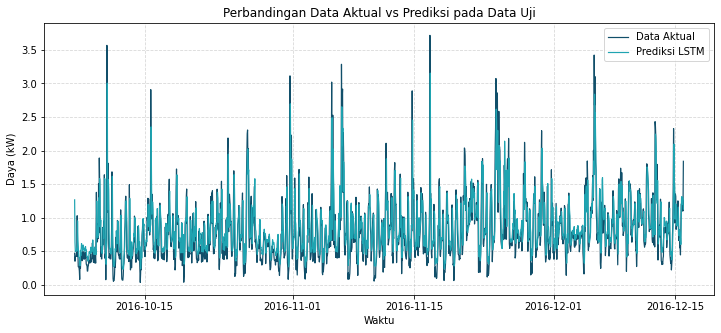

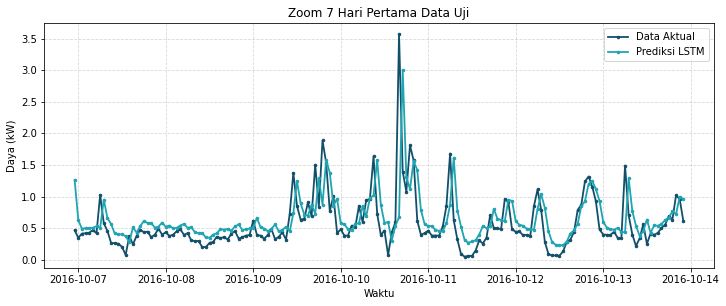

In [6]:
#202432044_DzakyHilmyHaidar
# 1. Plot Grafik Penurunan Loss Training terhadap Epoch
plt.figure(figsize=(10, 4))
plt.plot(train_losses, color='#114F6A', linewidth=2, label='Training Loss')
plt.plot(test_losses, color='#1FA4B1', linewidth=2, linestyle='--', label='Test Loss')
plt.title('Grafik Penurunan Loss Selama Pelatihan')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE, skala 0-1)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# 2. Prediksi pada data uji, lalu kembalikan ke skala asli (kW)
model.eval()
with torch.no_grad():
    pred_scaled = model(X_test.to(device)).cpu().numpy()
pred_kw = pred_scaled * (data_max - data_min) + data_min
actual_kw = y_test.numpy() * (data_max - data_min) + data_min

# 3. Metrik evaluasi + pembanding sederhana (naive: jam ini = jam sebelumnya)
mae = np.mean(np.abs(actual_kw - pred_kw))
rmse = np.sqrt(np.mean((actual_kw - pred_kw) ** 2))
r2 = 1 - np.sum((actual_kw - pred_kw) ** 2) / np.sum((actual_kw - actual_kw.mean()) ** 2)
naive_kw = X_test[:, -1, :].numpy() * (data_max - data_min) + data_min
rmse_naive = np.sqrt(np.mean((actual_kw - naive_kw) ** 2))
print(f'MAE   : {mae:.4f} kW')
print(f'RMSE  : {rmse:.4f} kW')
print(f'R2    : {r2:.4f}')
print(f'RMSE baseline naive (jam sebelumnya): {rmse_naive:.4f} kW')

# 4. Plot Grafik Perbandingan Data Aktual vs Hasil Prediksi Model (seluruh data uji)
plt.figure(figsize=(12, 5))
plt.plot(test_time, actual_kw, color='#114F6A', linewidth=1.2, label='Data Aktual')
plt.plot(test_time, pred_kw, color='#1FA4B1', linewidth=1.2, label='Prediksi LSTM')
plt.title('Perbandingan Data Aktual vs Prediksi pada Data Uji')
plt.xlabel('Waktu')
plt.ylabel('Daya (kW)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# 5. Zoom 7 hari pertama data uji (168 jam) agar detail pola harian terlihat
zoom = 168
plt.figure(figsize=(12, 4.5))
plt.plot(test_time[:zoom], actual_kw[:zoom], color='#114F6A', linewidth=1.8, marker='o', markersize=2.5, label='Data Aktual')
plt.plot(test_time[:zoom], pred_kw[:zoom], color='#1FA4B1', linewidth=1.8, marker='o', markersize=2.5, label='Prediksi LSTM')
plt.title('Zoom 7 Hari Pertama Data Uji')
plt.xlabel('Waktu')
plt.ylabel('Daya (kW)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

<div style="border: 1px solid #CBD5E1; border-radius: 10px; overflow: hidden; font-family: 'Segoe UI', sans-serif; margin-top: 16px;">
  <div style="background-color: #1FA4B1; color: #FFFFFF; padding: 10px 20px; font-weight: bold; font-size: 15px;">
    RINGKASAN ANALISIS PERFORMA MODEL
  </div>
  <div style="background-color: #FFFFFF; color: #334155; padding: 18px 20px; font-size: 14px; line-height: 1.6;">
    <p style="margin: 0;">
      <b>Kesimpulan Hasil Visualisasi:</b><br>
     Kurva Training Loss turun tajam pada 5 epoch pertama (±0,009 menjadi ±0,0035) lalu mendatar, sedangkan Test Loss stabil di kisaran 0,0013, menandakan model konvergen tanpa tanda overfitting. Test Loss yang lebih rendah dari Training Loss disebabkan oleh dropout pada fase pelatihan dan periode uji (Oktober–Desember) yang lebih tenang dibanding data latih yang memuat lonjakan konsumsi musim panas. Model menghasilkan MAE 0,2344 kW, RMSE 0,3459 kW, dan R² 0,4826, lebih baik secara tipis dibanding baseline naif (RMSE 0,3657 kW). Grafik menunjukkan prediksi mengikuti pola harian, namun cenderung meremehkan lonjakan konsumsi tinggi dan tampak tertinggal sekitar satu jam dari data aktual.
    </p>
  </div>
</div>